[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AGRIdigital-Climbat/PlantillaMapa/blob/main/04_Heladas/01_heladas.ipynb)

# Heladas: frecuencia, estacionalidad, duracion e intensidad
## PROSUCO - CLIMBAT | Analisis por municipio de Bolivia (GEE + Colab)

> **Area de estudio = tu GeoJSON.** Este notebook usa por defecto:
>
> `RUTA_AOI = "https://drive.google.com/file/d/11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N/view?usp=sharing"` (compartido `Cualquiera con el enlace`).
> El GeoJSON **siempre manda**: al cargarse, `roi`, `ZONA['bbox']`, `ZONA['centro']`
> y `area_km2` se recalculan desde el poligono. El `bbox` de CONFIG solo es respaldo
> si cambias a `AOI_MODE = "bbox"`.

**Orden de ejecucion:** 1) Instalacion -> 2) Autenticacion GEE (`EE_PROJECT`) ->
3) CONFIG (anos + satelite + umbrales) -> 4) AOI desde Drive -> 5) celdas del modulo.
Solo edita la celda **CONFIGURACION MAESTRA**.


In [1]:
# ============================================================
# 1.1 Instalación de librerías (ejecutar una sola vez en Colab)
# ============================================================

import importlib
import subprocess
import sys


def _asegurar(paquete, modulo=None):
    """Instala el paquete solo si no está disponible."""
    try:
        importlib.import_module(modulo or paquete)
    except ImportError:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", paquete]
        )


_asegurar("earthengine-api", "ee")
_asegurar("geemap")
_asegurar("geopandas")
_asegurar("pandas")
_asegurar("numpy")
_asegurar("matplotlib")

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

print("Librerías listas.")
print("earthengine-api:", ee.__version__)
print("geemap:", geemap.__version__)

Librerías listas.
earthengine-api: 1.7.39
geemap: 0.38.8


In [2]:
# ============================================================
# 1.2 Autenticación en Google Earth Engine
# ============================================================
# >>> REEMPLAZAR por el id del proyecto de Cloud de PROSUCO/CLIMBAT <<<

EE_PROJECT = "gen-lang-client-0636031685"

ee.Authenticate()
ee.Initialize(project=EE_PROJECT)

print("Earth Engine inicializado correctamente.")
print("Proyecto:", EE_PROJECT)

Earth Engine inicializado correctamente.
Proyecto: gen-lang-client-0636031685


## Configuración maestra

> **✏️ Esta es la única celda que se edita para diagnosticar una zona nueva.**

| Bloque | Qué define | Verificación previa |
|---|---|---|
| `ZONA` | nombre, bbox `[oeste, sur, este, norte]` y punto de vista | dibujar en [geojson.io](https://geojson.io) o en el editor GEE y copiar coordenadas |
| `AOI_MODE`/`RUTA_AOI` | fuente del AOI: `"bbox"` o `"auto"` (polígono **GeoJSON**) | exportar el polígono desde QGIS como **GeoJSON**; en `RUTA_AOI` se puede pegar un **enlace de Google Drive** (el notebook lo descarga solo) o una ruta de Drive |
| `PUNTOS_LOCALES` | manantiales/bofedales del saber local | levantamiento con las comunidades |
| `FECHA_INICIO / FECHA_FIN` | ventana analítica (**30+ años**) | default 1996-01-01 → 2026-12-31 |
| `CALENDARIO` | meses de siembra/cosecha y estación seca | observadores Yapuchiri |
| `UMBRALES` | todos los cortes analíticos en un solo lugar | criterio técnico + experiencia local |
| `ESCALAS` | resolución de cómputo (m); subir si la zona es grande | — |

In [3]:
# ===========================================================================
# CONFIGURACIÓN MAESTRA — ÚNICA CELDA QUE SE EDITA PARA CADA ZONA
# ===========================================================================

# --- 1. Zona de intervención ------------------------------------------------
# Fuente del AOI:
#   "bbox" -> usa el rectángulo ZONA["bbox"] de abajo (rápido, sin Drive)
#   "auto" -> usa un polígono .geojson. RUTA_AOI admite 3 formas:
#       * Enlace o ID de Google Drive  -> se DESCARGA solo (no subes nada a mano)
#           "https://drive.google.com/file/d/11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N/view?usp=sharing"
#           "11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N"
#       * Ruta en tu Drive ya montado  -> se lee directo, SIN copiar a /content
#           "/content/drive/MyDrive/CLIMBAT/zona.geojson"
#       * Carpeta en Drive             -> toma el único .geojson que contenga
#           "/content/drive/MyDrive/CLIMBAT"
AOI_MODE = "auto"
RUTA_AOI = "https://drive.google.com/file/d/11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N/view?usp=sharing"

ZONA = {
    # Coordenadas geocodificadas: Escoma (La Paz, Bolivia) ~3832 msnm
    # (solo se usan como respaldo cuando AOI_MODE = "bbox")
    "nombre": "Escoma, La Paz (prueba)",
    "bbox": [-69.33, -15.86, -68.93, -15.46],   # [oeste, sur, este, norte]
    "centro": [-69.1289, -15.6615],             # punto de vista del mapa
    "zoom": 10,
}

# --- 2. Puntos levantados con comunidades (saber local) ---------------------
# Listas de [longitud, latitud]. Dejar vacías si aún no hay levantamiento.
PUNTOS_LOCALES = {
    "manantiales": [],
    "bofedales": [],
}

# --- 3. Ventana analítica: 30+ años hacia atrás desde el año actual ---------
# Regla de la plantilla: 1996-01-01 -> 2026-12-31 (todo análisis de rango de años usa esta).
# Los datasets usan su período nativo si es mayor: CHIRPS 1981+ · ERA5-Land 1950+
# · JRC 1984–2021 · MODIS 2000+ (NDVI) / 2001+ (MCD12Q1 agricultura) · SMAP 2015+
FECHA_INICIO = "1996-01-01"
FECHA_FIN = "2026-12-31"

# --- 4. Calendario agrícola local (verificar con observadores Yapuchiri) ----
CALENDARIO = {
    "siembra": 11,       # mes de siembra (1–12)
    "cosecha": 4,        # mes de cosecha (1–12)
    "meses_estacion_seca": [5, 6, 7, 8, 9, 10],   # se usa en M10 (bofedales)
}

# --- 5. Umbrales analíticos (ajustar con criterio técnico y local) ----------
UMBRALES = {
    "helada_c": 0.0,               # °C mínima para contar un día de helada (M4)
    "helada_grave_c": -2.0,        # °C de helada grave (daño severo) (M4)
    "mes_seco_mm": 30.0,           # mm/mes para clasificar mes seco (M2)
    "spi_severo": -1.5,            # umbral de sequía severa SPI-3 (M5)
    "ndvi_anomalia_z": -1.5,       # anomalía NDVI severa (M7)
    "manantial_occurrencia": 100,  # % ocurrencia JRC mínima (M9)
    "manantial_drenaje_max": 50,   # celdas acumuladas máx. (cabeceras) (M9)
    "bofedal_altitud_min": 3000,   # msnm mínimo (M10)
    "bofedal_altitud_max": 5200,   # msnm máximo (M10)
    "bofedal_pendiente_max": 5.0,  # grados de pendiente máxima (M10)
    "bofedal_seasonality": 8,      # meses con agua JRC mínimos (M10)
    "bofedal_ndvi_seco": 0.25,     # NDVI mínimo en estación seca (M10)
    "clases_agricolas": [12, 14],  # LC_Type1 MCD12Q1: 12=cultivos, 14=mosaico (M11)
}

# --- 6. Escalas de cómputo (metros) -----------------------------------------
# Subir si la zona es muy grande (más rápido, menos detalle)
ESCALAS = {"clima": 5000, "modis": 250, "jrc": 90, "detalle": 30}
TILE_SCALE = 4

# ===========================================================================
# A partir de aquí no se edita nada
# ===========================================================================

MESES = list(range(1, 13))
MESES_ES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
            "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

roi = None   # se construye en la celda 1.4 (bbox o GeoJSON según AOI_MODE)
centro = None
ANIO_INI = int(FECHA_INICIO[:4])
ANIO_FIN = int(FECHA_FIN[:4])

# Años COMPLETOS (se excluye el año en curso de métricas y mapas anuales)
ANIOS_COMPLETOS = list(range(ANIO_INI, ANIO_FIN))
FILTRO_ANIOS_COMPLETOS = ee.Filter.calendarRange(
    ANIOS_COMPLETOS[0], ANIOS_COMPLETOS[-1], "year"
)

print("Zona:", ZONA["nombre"])
print("Ventana analítica:", FECHA_INICIO, "->", FECHA_FIN,
      f"({ANIO_FIN - ANIO_INI + 1} años calendario)")
print("Años completos para métricas:", ANIOS_COMPLETOS[0], "-", ANIOS_COMPLETOS[-1])
print("Calendario: siembra mes", CALENDARIO["siembra"],
      "| cosecha mes", CALENDARIO["cosecha"])
print("Umbrales activos:", UMBRALES)

Zona: Escoma, La Paz (prueba)
Ventana analítica: 1996-01-01 -> 2026-12-31 (31 años calendario)
Años completos para métricas: 1996 - 2025
Calendario: siembra mes 11 | cosecha mes 4
Umbrales activos: {'helada_c': 0.0, 'helada_grave_c': -2.0, 'mes_seco_mm': 30.0, 'spi_severo': -1.5, 'ndvi_anomalia_z': -1.5, 'manantial_occurrencia': 100, 'manantial_drenaje_max': 50, 'bofedal_altitud_min': 3000, 'bofedal_altitud_max': 5200, 'bofedal_pendiente_max': 5.0, 'bofedal_seasonality': 8, 'bofedal_ndvi_seco': 0.25, 'clases_agricolas': [12, 14]}


In [4]:
# ============================================================
# 1.3 Utilidades comunes (reutilizadas por todos los módulos)
# ============================================================

# Parámetros de reducción seguros contra "User memory limit exceeded":
#   bestEffort=True -> GEE sube la escala automáticamente si no cabe en memoria.
#   tileScale=8     -> divide el cálculo en tiles más pequeños (menos memoria c/u).
REDUCIR = dict(maxPixels=1e9, tileScale=8, bestEffort=True)
REDUCIR_AREA = dict(maxPixels=1e10, tileScale=16, bestEffort=True)


def apilar(imagenes, nombres):
    """Une imágenes de una banda en una sola imagen multibanda."""
    pila = None
    for img, nombre in zip(imagenes, nombres):
        banda = ee.Image(img).select(0).rename(nombre)
        pila = banda if pila is None else pila.addBands(banda)
    return pila


def reducir_bandas(imagenes, nombres, escala, tam=6, reductor=None, params=None):
    """reduceRegion de muchas bandas EN BLOQUES (una petición por bloque).

    Evita el error de memoria que ocurre al reducir de una sola vez una imagen
    con decenas de bandas (cada banda puede depender de cientos/miles de imágenes
    diarias). Devuelve un dict {nombre_banda: valor}.
    """
    reductor = reductor or ee.Reducer.mean()
    params = params or REDUCIR
    salida = {}
    for i in range(0, len(imagenes), tam):
        pila = apilar(imagenes[i:i + tam], nombres[i:i + tam])
        salida.update(
            pila.reduceRegion(reductor, roi, escala, **params).getInfo()
        )
    return salida


def composite_mensual(coleccion, anios, banda=None):
    """Reduce una colección diaria a UN compuesto por año-mes (una imagen c/u).

    Aligera ~30x la memoria de las climatologías de 30 años. `anios` debe listar
    solo años con dato (evita colecciones vacías). Con `banda`, deja una sola banda.
    """
    imgs = []
    for y in anios:
        for m in MESES:
            i0 = f"{y}-{m:02d}-01"
            i1 = (pd.Timestamp(i0) + pd.offsets.MonthBegin(1)).strftime("%Y-%m-%d")
            sub = coleccion.filterDate(i0, i1)
            if banda:
                sub = sub.select(banda)
            imgs.append(sub.mean().set("system:time_start", ee.Date(i0).millis()))
    return ee.ImageCollection(imgs)


def borde_aoi(color="FF0000", ancho=2):
    """Capa de SOLO el borde del AOI (relleno transparente).

    Evita que el relleno de color tape el mapa y meta ruido en la interpretación;
    deja el límite del área bien visible por encima de las demás capas.
    """
    return roi.style(color=color, fillColor="00000000", width=ancho)


def promediar_aoi(imagen, banda, escala):
    """Promedio de una banda dentro del AOI -> valor Python (o None)."""
    d = (
        imagen.select(banda)
        .reduceRegion(ee.Reducer.mean(), roi, escala, **REDUCIR)
        .getInfo()
    )
    return d.get(banda)


def serie_aoi(coleccion, banda, escala, bloque_anios=5):
    """Extrae el promedio del AOI por imagen, EN BLOQUES de años.

    Procesar la serie completa de una vez agota la memoria; por eso se trocea
    (por defecto cada 5 años) y se concatenan los resultados.
    """
    registros = []

    def _una_imagen(img):
        st = (
            img.select(banda)
            .reduceRegion(ee.Reducer.mean(), roi, escala, **REDUCIR)
        )
        return ee.Feature(None, {
            "date": ee.Date(img.get("system:time_start")).format("yyyy-MM-dd"),
            "valor": st.get(banda),
        })

    for y0 in range(ANIO_INI, ANIO_FIN + 1, bloque_anios):
        y1 = min(y0 + bloque_anios - 1, ANIO_FIN)
        sub = coleccion.filterDate(f"{y0}-01-01", f"{y1 + 1}-01-01")
        fc = ee.FeatureCollection(sub.map(_una_imagen)).getInfo()
        registros += [f["properties"] for f in fc["features"]]
    return registros


print("Utilidades: apilar(), reducir_bandas(), composite_mensual(), "
      "promediar_aoi(), serie_aoi()")

Utilidades: apilar(), reducir_bandas(), composite_mensual(), promediar_aoi(), serie_aoi()


In [5]:
# ============================================================
# 1.4 Área de estudio (AOI) y mapa base
# ============================================================
# Fuente del AOI (ver CONFIG):
#   AOI_MODE = "bbox" -> rectángulo ZONA["bbox"].
#   AOI_MODE = "auto" -> polígono desde un archivo .geojson en Google Drive.
#                        (En QGIS: Exportar -> Guardar entidades como -> GeoJSON,
#                         CRS EPSG:4326; subir a Drive y ajustar RUTA_AOI.)

def borde_aoi(color="FF0000", ancho=2):
    """Capa de SOLO el borde del AOI (relleno transparente)."""
    # ee.Geometry NO tiene .style() en la API de Python -> se envuelve en FeatureCollection
    fc = ee.FeatureCollection([ee.Feature(roi)])
    return fc.style(color=color, fillColor="00000000", width=ancho)


if AOI_MODE == "auto":
    from google.colab import drive
    drive.mount("/content/drive")

    import os
    import re
    import glob
    import geopandas as gpd

    ruta = str(RUTA_AOI).strip()

    # (a) Enlace o ID de Google Drive -> descarga automática (sin subir nada a mano).
    #     El archivo debe estar compartido como "Cualquiera con el enlace".
    if ruta.startswith("http") or ("/" not in ruta and len(ruta) >= 20):
        _asegurar("gdown")
        import gdown

        m = re.search(r"(?:/d/|id=)([-\w]{20,})", ruta)
        fid = m.group(1) if m else ruta
        ext = (
            ".zip" if ruta.lower().endswith(".zip") else
            ".kml" if ruta.lower().endswith(".kml") else
            ".gpkg" if ruta.lower().endswith(".gpkg") else
            ".geojson"
        )
        destino = "/content/zona_aoi" + ext
        print("Descargando AOI desde Google Drive...")
        gdown.download(id=fid, output=destino, quiet=False)
        ruta = destino
    # (b) Carpeta en Drive -> usar el único .geojson que contenga
    elif os.path.isdir(ruta):
        cands = sorted(glob.glob(os.path.join(ruta, "*.geojson")))
        if not cands:
            raise FileNotFoundError(f"No se encontró ningún .geojson en {ruta}")
        ruta = cands[0]
    # (c) Ruta de archivo en el Drive montado -> se lee directo (sin copiar)

    gdf = gpd.read_file(ruta).to_crs(4326)
    try:
        geometria = gdf.geometry.union_all()      # shapely >= 2 (disuelve features)
    except AttributeError:
        geometria = gdf.geometry.unary_union      # shapely < 2
    gdf = gpd.GeoDataFrame(geometry=[geometria], crs=4326)

    roi = geemap.geopandas_to_ee(gdf).geometry()

    minx, miny, maxx, maxy = geometria.bounds
    ZONA["bbox"] = [minx, miny, maxx, maxy]
    ZONA["centro"] = [(minx + maxx) / 2, (miny + maxy) / 2]
    ZONA["zoom"] = 10
    print("AOI cargado desde:", ruta)
else:
    roi = ee.Geometry.Rectangle(ZONA["bbox"], proj="EPSG:4326", geodesic=False)

centro = ee.Geometry.Point(ZONA["centro"])
area_km2 = roi.area(maxError=1e6).divide(1e6).getInfo()

Map_aoi = geemap.Map()
Map_aoi.centerObject(roi, ZONA["zoom"])
Map_aoi.add_basemap("HYBRID")
Map_aoi.addLayer(borde_aoi(), {}, f"AOI: {ZONA['nombre']}")

# Puntos del saber local (si se cargaron en CONFIG)
for tipo, color in (("manantiales", "cyan"), ("bofedales", "magenta")):
    coords = PUNTOS_LOCALES.get(tipo, [])
    if coords:
        Map_aoi.addLayer(
            ee.Geometry.MultiPoint(coords),
            {"color": color},
            f"{tipo.capitalize()} (saber local)",
        )

print(f"Zona: {ZONA['nombre']}")
print(f"Área del AOI: {area_km2:,.1f} km²")
print(f"Extensión (bbox): {ZONA['bbox']}")
print("Puntos de saber local cargados:",
      {k: len(v) for k, v in PUNTOS_LOCALES.items()})

Map_aoi

Mounted at /content/drive
Descargando AOI desde Google Drive...


Downloading...
From: https://drive.google.com/uc?id=11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N
To: /content/zona_aoi.geojson
100%|██████████| 6.32k/6.32k [00:00<00:00, 8.36MB/s]


AOI cargado desde: /content/zona_aoi.geojson
Zona: Escoma, La Paz (prueba)
Área del AOI: 5,638.9 km²
Extensión (bbox): [-68.088142, -19.88671, -67.170426, -19.050138]
Puntos de saber local cargados: {'manantiales': 0, 'bofedales': 0}


Map(center=[-19.436538457151876, -67.61413826547425], controls=(WidgetControl(options=['position', 'transparen…

# M4. Heladas: frecuencia, estacionalidad, duración e intensidad
**Dimensiones:** *frecuencia* (días de helada por año), *estacionalidad* (meses de helada),
*ocurrencia* (% de años con helada), *intensidad* (heladas graves ≤ −2 °C), *duración* (ver nota).

**Definición operativa:** día de helada = temperatura mínima del aire ≤ `UMBRALES["helada_c"]`
(0 °C por defecto). Helada grave = ≤ −2 °C (umbral de daño severo típico en cultivos andinos).

* **Primario:** Tmin diaria de `ECMWF/ERA5_LAND/DAILY_AGGR` (1950+).
* **Alternativa:** LST nocturna `MODIS/061/MOD11A1` (1 km) — más detalle espacial, pero mide
  *superficie*: en laderas con cobertura vegetal subestima el aire; puede sobreestimar heladas
  en suelos desnudos nocturnos.
* **Validación obligatoria:** contrastar con la red de observadores agroclimáticos y estaciones
  CLIMBAT: a 11 km el modelo no ve la inversión térmica del fondo del valle.

Punto: centroide del AOI
Umbrales: helada ≤ 0.0 °C | grave ≤ -2.0 °C
Imágenes LST nocturnas (compuestos de 8 días): 1224

>>> Extrayendo serie de LST nocturna por bloques (5 años cada uno)...
  · bloque 1996-2000 ... 40 compuestos OK
  · bloque 2001-2005 ... 229 compuestos OK
  · bloque 2006-2010 ... 230 compuestos OK
  · bloque 2011-2015 ... 230 compuestos OK
  · bloque 2016-2020 ... 230 compuestos OK
  · bloque 2021-2025 ... 230 compuestos OK

Compuestos totales: 1153
Rango LST nocturna: -20.87 a 12.49 °C

--- Días de helada (estimados) por año con MODIS ---
 anio  compuestos_con_helada  compuestos_graves  dias_est_helada  dias_est_grave
 2000                     26                 24              208             192
 2001                     20                 15              160             120
 2002                     19                 16              152             128
 2003                     21                 17              168             136
 2004                     21

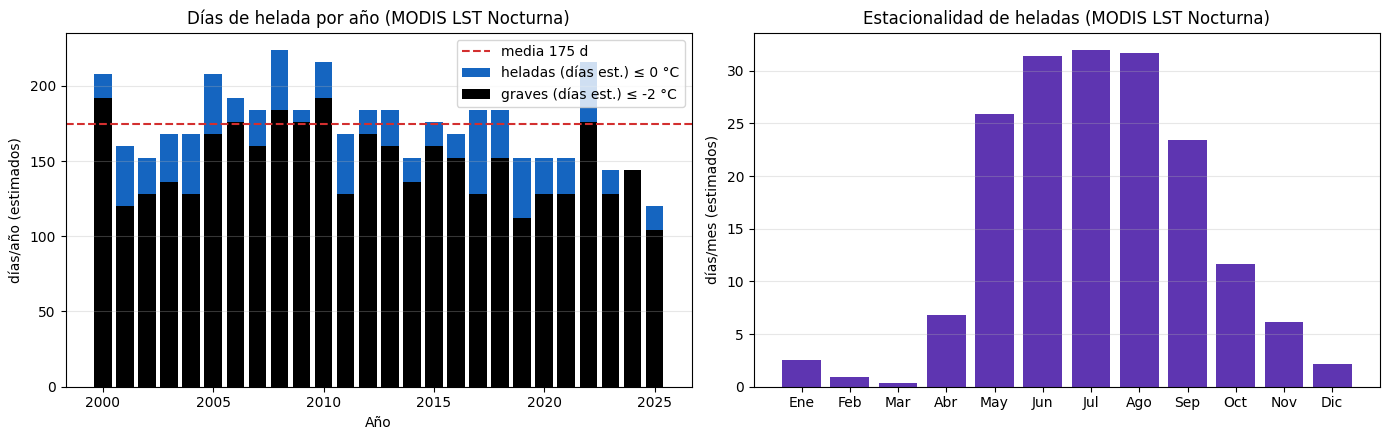

In [6]:
# ============================================================
# M4.1 (BIS) Días de helada con MODIS LST Nocturna (1 km)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ee
%matplotlib inline

# --- 1) Punto de referencia (idéntico a tu M4.1) -----------------
try:
    punto = ee.Geometry.Point([LON, LAT])
    print(f"Punto: LON={LON}, LAT={LAT}")
except NameError:
    punto = roi.centroid(maxError=1000)
    print("Punto: centroide del AOI")

# --- 2) Umbrales (idénticos a tu M4.1) ---------------------------
if "UMBRALES" not in dir():
    UMBRALES = {"helada_c": 0, "helada_grave_c": -2}
U_FRIO  = UMBRALES.get("helada_c", 0)
U_GRAVE = UMBRALES.get("helada_grave_c", -2)
print(f"Umbrales: helada ≤ {U_FRIO} °C | grave ≤ {U_GRAVE} °C")

# --- 3) Colección base: MODIS LST Nocturna -----------------------
# Usamos el producto de 8 días MOD11A2 y extraemos la banda nocturna
tmin_base = (
    ee.ImageCollection("MODIS/061/MOD11A2")
    .filterDate(FECHA_INICIO, FECHA_FIN)
    .filterBounds(punto)
    .map(lambda i: i.select("LST_Night_1km")
                    .multiply(0.02)        # Aplicar factor de escala de MODIS
                    .subtract(273.15)      # Convertir de Kelvin a Celsius
                    .rename("tmin")
                    .set("system:time_start", i.get("system:time_start")))
)
print("Imágenes LST nocturnas (compuestos de 8 días):", tmin_base.size().getInfo())

# --- 4) Extraer la serie por bloques de años (función idéntica) ---
def _get_region_bloques(col, punto, anios, chunk_anios=5, escala=1000):
    """Extrae la serie por bloques de años. Nota: escala de 1000m para MODIS."""
    frames = []
    for i in range(0, len(anios), chunk_anios):
        bloque = anios[i:i + chunk_anios]
        print(f"  · bloque {bloque[0]}-{bloque[-1]} ...", end=" ")
        col_b = col.filter(ee.Filter.calendarRange(bloque[0], bloque[-1], "year"))
        try:
            region = col_b.getRegion(punto, scale=escala).getInfo()
            cab = region[0]
            df_b = pd.DataFrame(region[1:], columns=cab)
            frames.append(df_b)
            print(f"{len(df_b)} compuestos OK")
        except Exception as e:
            print(f"FALLÓ: {e}")
    if not frames:
        raise RuntimeError("Ningún bloque se pudo extraer.")
    return pd.concat(frames, ignore_index=True)

print("\n>>> Extrayendo serie de LST nocturna por bloques (5 años cada uno)...")
anios_h = list(ANIOS_COMPLETOS)
df_raw = _get_region_bloques(tmin_base, punto, anios_h, chunk_anios=5, escala=1000)

# --- 5) Normalizar y contar (la lógica cambia ligeramente) --------
df_raw["date"] = pd.to_datetime(df_raw["time"], unit="ms")
df_raw["tmin"] = pd.to_numeric(df_raw["tmin"], errors="coerce")
df_diario = (df_raw.dropna(subset=["tmin"])
             .sort_values("date").reset_index(drop=True))
df_diario["anio"] = df_diario["date"].dt.year
df_diario["mes"]  = df_diario["date"].dt.month

print(f"\nCompuestos totales: {len(df_diario)}")
print(f"Rango LST nocturna: {df_diario['tmin'].min():.2f} a {df_diario['tmin'].max():.2f} °C")

# La "helada" se define si la LST nocturna del compuesto de 8 días está por debajo del umbral.
# Un compuesto por debajo del umbral indica que al menos una noche de ese período fue de helada.
df_diario["helada"] = (df_diario["tmin"] <= U_FRIO).astype(int)
df_diario["grave"]  = (df_diario["tmin"] <= U_GRAVE).astype(int)

# Agrupamos por año, pero ahora contamos el número de compuestos con helada.
# Para estimar días, multiplicamos por 8 (días que representa cada compuesto).
df_heladas = (df_diario
              .groupby("anio")[["helada", "grave"]]
              .sum()
              .reset_index()
              .rename(columns={"helada": "compuestos_con_helada", "grave": "compuestos_graves"}))
df_heladas["dias_est_helada"] = df_heladas["compuestos_con_helada"] * 8
df_heladas["dias_est_grave"] = df_heladas["compuestos_graves"] * 8

print("\n--- Días de helada (estimados) por año con MODIS ---")
print(df_heladas.to_string(index=False))

# --- 6) Gráficos (adaptados para mostrar días estimados) ---------
media_h = df_heladas["dias_est_helada"].mean()

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))

ejes[0].bar(df_heladas["anio"], df_heladas["dias_est_helada"],
            color="#1565c0", label=f"heladas (días est.) ≤ {U_FRIO:.0f} °C")
ejes[0].bar(df_heladas["anio"], df_heladas["dias_est_grave"],
            color="#000000", label=f"graves (días est.) ≤ {U_GRAVE:.0f} °C")
if media_h > 0:
    ejes[0].axhline(media_h, color="#d32f2f", ls="--",
                    label=f"media {media_h:.0f} d")
ejes[0].set_title("Días de helada por año (MODIS LST Nocturna)")
ejes[0].set_xlabel("Año"); ejes[0].set_ylabel("días/año (estimados)")
ejes[0].legend(); ejes[0].grid(alpha=0.3, axis="y")

# Estacionalidad (también en base a compuestos)
df_mes = (df_diario
          .groupby(["anio", "mes"])["helada"].sum()
          .groupby("mes").mean()
          .reindex(MESES, fill_value=0)
          .reset_index())
df_heladas_mes = pd.DataFrame({
    "mes": MESES_ES,
    "dias_promedio": df_mes["helada"].values * 8, # Convertir a días estimados
})

ejes[1].bar(df_heladas_mes["mes"], df_heladas_mes["dias_promedio"],
            color="#5e35b1")
ejes[1].set_title("Estacionalidad de heladas (MODIS LST Nocturna)")
ejes[1].set_ylabel("días/mes (estimados)"); ejes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

In [36]:
# ============================================================
# M4.2 Mapa de heladas con MODIS LST Nocturna (1 km)
# Selector de año — leyenda FUERA del mapa (sin acumulación)
# ============================================================

import ipywidgets as widgets
from IPython.display import display
import ee, geemap

if "roi" not in globals() or roi is None:
    raise RuntimeError("roi es None. Recarga tu GeoJSON antes de este bloque.")
if isinstance(roi, ee.FeatureCollection):
    roi = roi.geometry()

if "UMBRALES" not in dir():
    UMBRALES = {"helada_c": 0, "helada_grave_c": -2}
U_FRIO  = UMBRALES.get("helada_c", 0)
U_GRAVE = UMBRALES.get("helada_grave_c", -2)
print(f"Umbrales: helada ≤ {U_FRIO} °C | grave ≤ {U_GRAVE} °C")

# --- MODIS LST nocturna -> °C ---
lst_noche = (
    ee.ImageCollection("MODIS/061/MOD11A2")
    .filterDate(FECHA_INICIO, FECHA_FIN)
    .filterBounds(roi)
    .filter(ee.Filter.calendarRange(ANIOS_COMPLETOS[0],
                                    ANIOS_COMPLETOS[-1], "year"))
    .map(lambda i: i.select("LST_Night_1km")
                    .multiply(0.02)
                    .subtract(273.15)
                    .rename("tmin")
                    .set("system:time_start", i.get("system:time_start")))
)
print("Compuestos de 8 días (MODIS):", lst_noche.size().getInfo())

# --- Máscara binaria con cast explícito a int16 ---
def _marcar(img):
    return (img.lte(U_FRIO)
            .rename("h")
            .unmask(0)
            .toInt16()
            .set("system:time_start", img.get("system:time_start")))
helada_modis = lst_noche.map(_marcar)

# --- Compuestos con helada por año (merge homogéneo en int16) ---
def _heladas_anio(anio):
    coleccion_anio = helada_modis.filter(ee.Filter.calendarRange(anio, anio, "year"))
    cero = ee.Image.constant(0).rename("h").toInt16().clip(roi)
    return ee.ImageCollection([cero]).merge(coleccion_anio).sum().rename("h").clip(roi)

# --- Tope dinámico ---
anio_default = int(ANIOS_COMPLETOS[-1])
stats = _heladas_anio(anio_default).reduceRegion(
    ee.Reducer.minMax(), roi, 1000,
    maxPixels=1e13, bestEffort=True, tileScale=8,
).getInfo()

print(f"Rango compuestos con helada en {anio_default}: {stats}")
max_real = stats.get("h_max") or 0
tope = int(min(46, max(4, (int(max_real) // 4 + 1) * 4)))
print(f"Tope leyenda: {tope} compuestos (~{tope*8} días)")

vis_h = {"min": 0, "max": tope,
         "palette": ["ffffff", "cfe8ff", "9ec9ff", "4a90e2", "1c4fb0", "0a1f5c"]}

# --- Mapa + selector ---
Map_m4 = geemap.Map(layout=widgets.Layout(width="100%", height="600px"))
Map_m4.centerObject(roi, ZONA["zoom"] - 1)
Map_m4.add_basemap("HYBRID")
Map_m4.addLayer(borde_aoi(), {}, "AOI")

PREFIJO = "HEL_"

w_anio = widgets.Dropdown(
    options=list(ANIOS_COMPLETOS),
    value=anio_default,
    description="Año:",
    layout=widgets.Layout(width="200px"),
)

# --- Leyenda HTML externa ---
def _html_leyenda(anio):
    paleta = vis_h["palette"]
    n = len(paleta)
    stops = [f"#{c} {i/(n-1)*100:.1f}%" for i, c in enumerate(paleta)]
    gradiente = "linear-gradient(to right, " + ", ".join(stops) + ")"
    vals = [0, tope * 0.25, tope * 0.5, tope * 0.75, tope]
    etiquetas_html = "".join(f"<span>{v:.0f}</span>" for v in vals)
    return (
        '<div style="margin-top:10px; padding:10px 14px; background:#fafafa; '
        'border:1px solid #d0d0d0; border-radius:8px; max-width:640px; '
        'font-family: -apple-system, Segoe UI, Arial, sans-serif;">'
        '<div style="font-weight:600; font-size:13px; color:#222; margin-bottom:8px;">'
        f'Compuestos de 8 días con helada — <b>{anio}</b> '
        f'<span style="color:#666; font-weight:400;">'
        f'(0 – {tope} compuestos · equivale a 0 – {tope*8} días)</span>'
        '</div>'
        f'<div style="height:18px; background:{gradiente}; '
        'border:1px solid #888; border-radius:4px;"></div>'
        '<div style="display:flex; justify-content:space-between; '
        'font-size:11px; color:#333; margin-top:3px;">'
        f'{etiquetas_html}'
        '</div>'
        '<div style="font-size:11px; color:#666; margin-top:6px; font-style:italic;">'
        'Menos heladas &larr; blanco · azul intenso &rarr; más heladas'
        '</div>'
        '</div>'
    )

w_leyenda = widgets.HTML(value=_html_leyenda(anio_default))

# --- Callback con referencia segura a la capa activa ---
_capa_actual = None

def _actualizar(change=None):
    global _capa_actual
    anio = w_anio.value

    # (a) Eliminar capa anterior con referencia segura
    if _capa_actual is not None:
        try:
            Map_m4.remove_layer(_capa_actual)
        except Exception:
            pass
        _capa_actual = None

    # (b) Respaldo: limpiar cualquier capa huérfana con el prefijo
    for l in list(Map_m4.layers):
        if getattr(l, "name", "").startswith(PREFIJO):
            try:
                Map_m4.remove_layer(l)
            except Exception:
                pass

    # (c) Agregar la nueva capa
    nombre = f"{PREFIJO}Heladas MODIS {anio}"
    Map_m4.addLayer(_heladas_anio(anio), vis_h, nombre)

    # (d) Guardar referencia a la capa recién agregada
    for l in reversed(Map_m4.layers):
        if getattr(l, "name", "") == nombre:
            _capa_actual = l
            break

    # (e) Actualizar leyenda externa
    w_leyenda.value = _html_leyenda(anio)

w_anio.observe(_actualizar, "value")
_actualizar()

# --- Layout ---
display(widgets.VBox([
    widgets.HTML(
        f"<h4 style='margin:4px 0;'>Heladas con MODIS LST Nocturna (1 km) — "
        f"umbral tmin ≤ {U_FRIO} °C — 1 compuesto = 8 días</h4>"
    ),
    w_anio,
    Map_m4,
    w_leyenda,
]))

Umbrales: helada ≤ 0.0 °C | grave ≤ -2.0 °C
Compuestos de 8 días (MODIS): 1189
Rango compuestos con helada en 2025: {'h_max': 39, 'h_min': 0}
Tope leyenda: 40 compuestos (~320 días)


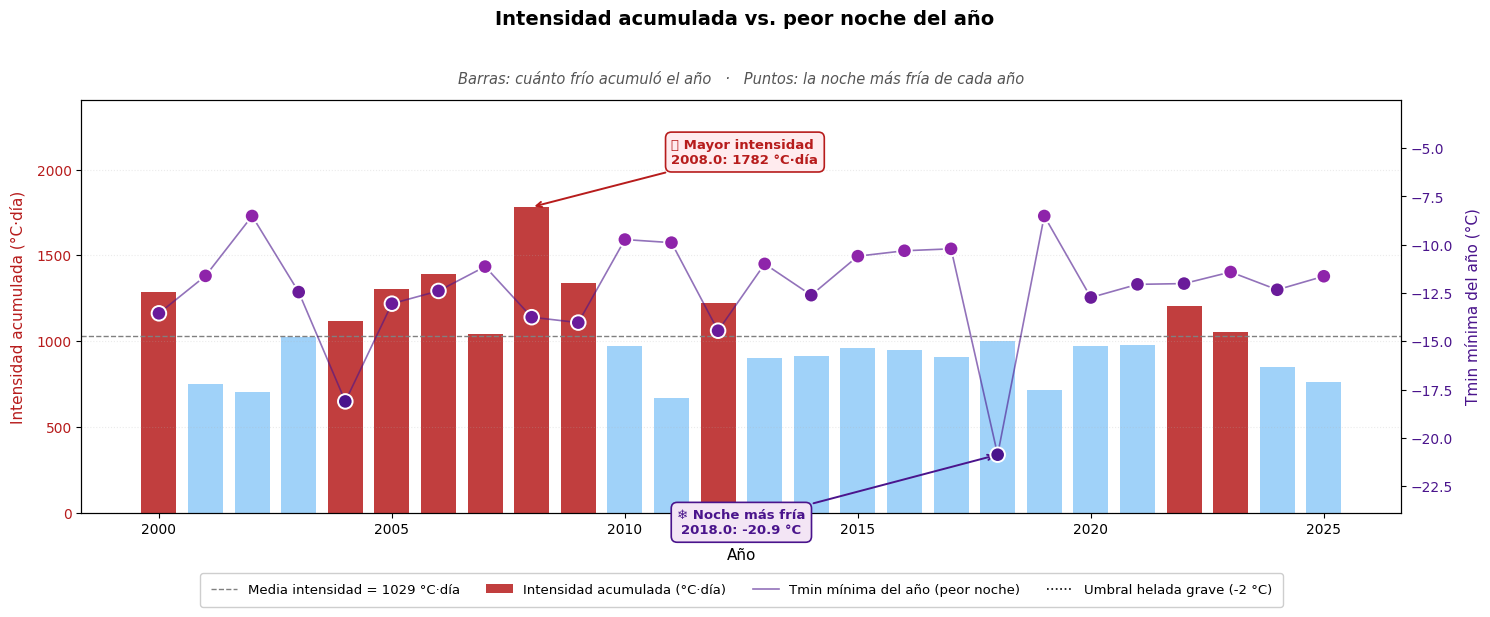

In [26]:
# ============================================================
# M4.8b Comparación visual: intensidad vs Tmin mínima
# ============================================================
# Combina en una sola vista las dos preguntas:
#   - Barra = intensidad acumulada (cuánto frío total)
#   - Punto = Tmin mínima del año (la peor noche)
# Los colores del punto indican la gravedad del récord.

fig, ax = plt.subplots(figsize=(15, 6.5))

# --- Barras de intensidad (eje izquierdo) --------------------------------
media_int = df_int["intensidad"].mean()
col_barras = ["#b71c1c" if v > media_int else "#90caf9"
              for v in df_int["intensidad"]]
ax.bar(df_int["anio"], df_int["intensidad"],
       color=col_barras, alpha=0.85, width=0.75,
       label="Intensidad acumulada (°C·día)")

ax.axhline(media_int, color="grey", ls="--", lw=1,
           label=f"Media intensidad = {media_int:.0f} °C·día")

ax.set_ylabel("Intensidad acumulada (°C·día)",
              color="#b71c1c", fontsize=11, labelpad=8)
ax.tick_params(axis="y", labelcolor="#b71c1c", labelsize=10)
ax.set_xlabel("Año", fontsize=11, labelpad=8)
ax.tick_params(axis="x", labelsize=10)
ax.grid(alpha=0.25, axis="y", linestyle=":")

# Margen superior para que los rótulos no choquen con el borde
ax.set_ylim(0, df_int["intensidad"].max() * 1.35)

# --- Puntos de Tmin mínima (eje derecho) ---------------------------------
ax2 = ax.twinx()

def _color_tmin(t):
    if t <= -15:  return "#4a148c"   # violeta: récord extremo
    if t <= -12:  return "#6a1b9a"   # morado: muy frío
    if t <=  -8:  return "#8e24aa"   # lila: frío
    return "#ba68c8"                 # lila claro: moderado

colores_p = [_color_tmin(t) for t in df_int["tmin_min"]]

# Línea que conecta los puntos
ax2.plot(df_int["anio"], df_int["tmin_min"],
         lw=1.2, color="#4a148c", alpha=0.6, zorder=2,
         label="Tmin mínima del año (peor noche)")
# Puntos con borde blanco
ax2.scatter(df_int["anio"], df_int["tmin_min"],
            s=110, c=colores_p, edgecolors="white",
            linewidths=1.4, zorder=5)

ax2.axhline(U_GRAVE, color="black", ls=":", lw=1.2,
            label=f"Umbral helada grave ({U_GRAVE:.0f} °C)")
ax2.set_ylabel("Tmin mínima del año (°C)",
               color="#4a148c", fontsize=11, labelpad=8)
ax2.tick_params(axis="y", labelcolor="#4a148c", labelsize=10)

# Margen inferior para que los puntos no choquen con el eje x
margen = 3
ax2.set_ylim(df_int["tmin_min"].min() - margen,
             df_int["tmin_min"].max() + margen * 2)

# --- Récords absolutos: anotaciones --------------------------------------
y_int_max  = df_int.loc[df_int["intensidad"].idxmax()]
y_tmin_min = df_int.loc[df_int["tmin_min"].idxmin()]

# Récord de intensidad (arriba de su barra)
ax.annotate(
    f"🏆 Mayor intensidad\n{y_int_max['anio']}: {y_int_max['intensidad']:.0f} °C·día",
    xy=(y_int_max["anio"], y_int_max["intensidad"]),
    xytext=(y_int_max["anio"] + 3, y_int_max["intensidad"] * 1.18),
    fontsize=9.5, weight="bold", color="#b71c1c",
    ha="left", va="center",
    arrowprops=dict(arrowstyle="->", color="#b71c1c", lw=1.4),
    bbox=dict(boxstyle="round,pad=0.45",
              facecolor="#ffebee", edgecolor="#b71c1c",
              linewidth=1.2),
)

# Noche más fría (debajo de su punto)
ax2.annotate(
    f"❄ Noche más fría\n{y_tmin_min['anio']}: {y_tmin_min['tmin_min']:.1f} °C",
    xy=(y_tmin_min["anio"], y_tmin_min["tmin_min"]),
    xytext=(y_tmin_min["anio"] - 5.5, y_tmin_min["tmin_min"] - 3.5),
    fontsize=9.5, weight="bold", color="#4a148c",
    ha="center", va="center",
    arrowprops=dict(arrowstyle="->", color="#4a148c", lw=1.4),
    bbox=dict(boxstyle="round,pad=0.45",
              facecolor="#f3e5f5", edgecolor="#4a148c",
              linewidth=1.2),
)

# --- Leyenda combinada (fuera del área, arriba) --------------------------
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2,
          loc="upper center",
          bbox_to_anchor=(0.5, -0.13),
          ncol=4, fontsize=9.5, framealpha=0.95,
          edgecolor="#cccccc", borderpad=0.8)

# --- Título principal y subtítulo ----------------------------------------
fig.suptitle("Intensidad acumulada vs. peor noche del año",
             fontsize=14, weight="bold", y=0.98)
ax.set_title(
    "Barras: cuánto frío acumuló el año   ·   "
    "Puntos: la noche más fría de cada año",
    fontsize=10.5, color="#555555", pad=12, style="italic",
)

plt.tight_layout(rect=[0, 0.02, 1, 0.96])
plt.show()

## Interpretación de M4
* **Frecuencia** (días/año) es la métrica accionable para CLIMBAT: define cuántas alertas
  dispara una temporada y cuántas noches de protección (mallas, riego por aspersión) se necesitan.
* **Estacionalidad:** los meses con más helada deben quedar fuera de la siembra/cosecha sensible;
  compara con el `CALENDARIO` de CONFIG.
* **Intensidad:** los días graves (≤ −2 °C) son los que realmente dañan; la red de sensores
  CLIMBAT debe priorizarse en las zonas rojas del mapa.
* **Duración:** la serie diaria permite calcular la máxima racha consecutiva de heladas (agregar
  con `df` diario si se necesita: ver nota en M5 con la función de racha).

**Preguntas guía**
1. ¿Los meses de helada del mapa coinciden con las heladas que reportan los agricultores?
2. ¿Dónde instalarían las estaciones CLIMBAT: en las zonas con más días/año o en las de más área?
3. ¿El peor año de la serie recuerdan haberlo vivido?

## Cierre: checklist del modulo

- [ ] Parte base ejecutada (instalacion, autenticacion GEE, CONFIG, AOI del GeoJSON).
- [ ] Mapa(s) revisados contra el borde rojo del AOI (el GeoJSON siempre manda).
- [ ] Serie/tabla leidas + interpretacion contrastada con saber local (Yapuchiri/PACHASOL).
- [ ] Periodo y dataset anotados junto a cada numero (p. ej. `CHIRPS 1981-2025`).

### Como cambiar de satelite o de anos (patron en todos los modulos)

```python
FECHA_INICIO = "1996-01-01"  # en la celda CONFIG: ventana analitica
FECHA_FIN = "2026-12-31"
# --- Primario (default) ---
precip = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
# --- Alternativas: comentar la primaria y descomentar la elegida ---
# precip = ee.ImageCollection("NASA/GPM_L3/IMERG_V06")
# Cada alternativa indica resolucion, periodo y para que sirve.
```
